# Optional self-study: geometry–time operator evaluation
**Outside mandatory Weeks 1–22.** Prerequisites: Week 15 geometry/SDF and
Week 21 rollout/phase; Week 18 causality is useful. Study budget: **150–180
minutes (estimated)**. Read the editable lecture for derivations, rubric
and source limits. This notebook uses tiny manufactured arrays, not CFD,
and does no fitting, downloads or GPU work. No LinkedIn content is used.


**Reference-answer edition. Attempt the student notebook first. All four checks are enabled here.**


In [1]:
from pathlib import Path
import sys, time
import numpy as np
import matplotlib.pyplot as plt
started = time.perf_counter()
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'flowmllab'/'geometry_time_bridge.py').is_file()), None)
if root is None:
    raise RuntimeError('Open this notebook in a full FlowMLLab checkout/ZIP; the flowmllab source folder is required.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from flowmllab import geometry_time_bridge as bridge
print('CPU / NumPy', np.__version__, '| manufactured arrays only | no retained-file writes')


CPU / NumPy 2.2.6 | manufactured arrays only | no retained-file writes


## Worked example 1: geometry groups before history windows
The oscillator rate is not Reynolds number. The field formula is the same
across shapes; SDF changes the scoring domain. It models no geometry-induced
flow response. Positive SDF is fluid. With 25 frames and history four, one
case gives 21 windows; eight/two/two cases give 168/42/42 windows.


windows: {'train': 168, 'validation': 42, 'test': 42}
first window (case, inclusive start, target): ('g0_rate0.2', 0, 4)
raw manufactured field bytes: 2040000


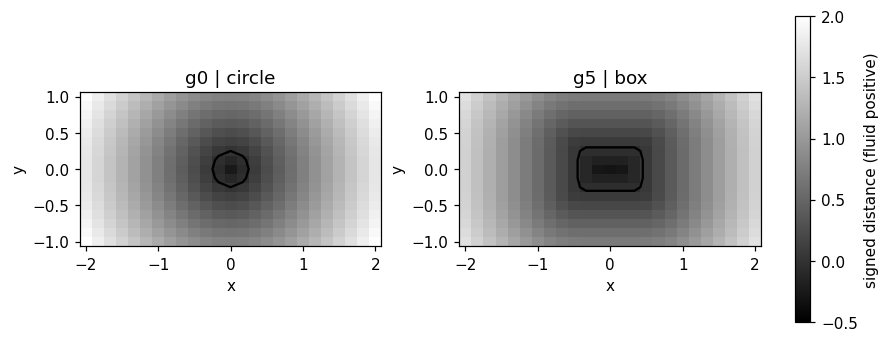

In [2]:
cases = bridge.manufactured_cases()
partitions = dict(train=['g0','g1','g3','g4'], validation=['g2'], test=['g5'])
records = bridge.split_before_windows(cases, partitions, history=4)
print('windows:', {name:len(rows) for name,rows in records.items()})
print('first window (case, inclusive start, target):', records['train'][0])
print('raw manufactured field bytes:', sum(c['values'].nbytes for c in cases.values()))
fig, axes = plt.subplots(1,2,figsize=(8,3),layout='constrained')
for ax,key in zip(axes,['g0_rate0.2','g5_rate0.2']):
    c = cases[key]
    im=ax.pcolormesh(c['x'],c['y'],c['sdf'],cmap='gray',shading='nearest',vmin=-.5,vmax=2)
    ax.contour(c['x'],c['y'],c['sdf'],levels=[0],colors='black')
    ax.set(title=c['geometry_id']+' | '+c['family'],xlabel='x',ylabel='y',aspect='equal')
fig.colorbar(im,ax=axes,label='signed distance (fluid positive)')
plt.show()


## Worked example 2: masks and weighting
Errors 2 (fluid), 100 (solid) in case A; errors 3,3 (fluid) in case B.
Case MSEs are 4 and 9; equal-case mean = 6.5; pooled mean = 22/3.
Shape validation prevents an accidental second batch axis.


In [3]:
prediction=np.array([[[[2.],[100.]]],[[[3.],[3.]]]])
truth=np.zeros_like(prediction)
fluid=np.array([[[True,False]],[[True,True]]])
loss=bridge.masked_mse(prediction,truth,fluid)
print(loss)
np.testing.assert_allclose(loss['per_case'],[4,9])
assert np.isclose(loss['equal_case'],6.5) and np.isclose(loss['pooled'],22/3)


{'per_case': array([4., 9.]), 'equal_case': 6.5, 'pooled': 7.333333333333333}


## Worked example 3: poison the future
Predictor = latest history value + 0.25. Initialize once with states 1, 2.
Repeated true-history prediction is a valid one-step task; it is a different
protocol from feedback. A counterexample must distinguish them.


In [4]:
observed=np.arange(1.,8.)[:,None]
poisoned=observed.copy(); poisoned[2:]+=1000
predictor=lambda h: h[-1]+.25
auto=bridge.autonomous(predictor,observed[:2],5)
tf=bridge.teacher_forced(predictor,observed,2)
auto_poison=bridge.autonomous(predictor,poisoned[:2],5)
tf_poison=bridge.teacher_forced(predictor,poisoned,2)
print('autonomous:',auto.ravel(),'teacher-forced:',tf.ravel())
print('prediction invariant:',np.array_equal(auto,auto_poison),
      '| teacher-forced control invariant:',np.array_equal(tf,tf_poison))
print('scores before/after poison:',np.mean((auto-observed[2:])**2),np.mean((auto_poison-poisoned[2:])**2))
assert np.array_equal(auto,auto_poison) and not np.array_equal(tf,tf_poison)


autonomous: [2.25 2.5  2.75 3.   3.25] teacher-forced: [2.25 3.25 4.25 5.25 6.25]
prediction invariant: True | teacher-forced control invariant: False
scores before/after poison: 6.1875 1004506.1875


## Worked example 4: amplitude, phase and undefined values
A supplied frequency is known here. Phase uses the first sample as origin.
±90° errors cancel in signed mean but have 90° absolute error. A constant
signal has no identifiable oscillatory phase. Keep the missing-pair count.


In [5]:
t=13.5+np.arange(100)*.1
signal=.4+2*np.sin(2*np.pi*.2*(t-t[0])+.3)
print('known sinusoid:',bridge.harmonic_summary(t,signal,.2))
print('constant:',bridge.harmonic_summary(t,np.ones_like(t),.2))
print('cancellation:',bridge.phase_metrics([np.pi/2,-np.pi/2,None],[0.,0.,0.]))
print('2-degree crossing:',bridge.phase_metrics([np.deg2rad(-179)],[np.deg2rad(179)]))
print('unwrapped frequency drift over 20 units:',2*np.pi*(.205-.2)*20)


known sinusoid: {'offset': 0.4000000000000002, 'amplitude': 2.0000000000000004, 'phase': 0.3000000000000007, 'frequency': 0.2, 'phase_origin': 13.5, 'residual_mse': 1.1256008053129351e-30, 'r_squared': 1.0}
constant: {'offset': 0.9999999999999997, 'amplitude': 5.904367903688329e-17, 'phase': None, 'frequency': 0.2, 'phase_origin': 13.5, 'residual_mse': 1.1339875512552044e-31, 'r_squared': None}
cancellation: {'valid_pairs': 2, 'undefined_pairs': 1, 'signed_mean': 0.0, 'mean_absolute': 1.5707963267948966, 'rms': 1.5707963267948966}
2-degree crossing: {'valid_pairs': 1, 'undefined_pairs': 0, 'signed_mean': 0.034906585039886445, 'mean_absolute': 0.034906585039886445, 'rms': 0.034906585039886445}
unwrapped frequency drift over 20 units: 0.6283185307179556


## Your four exercises
Each task is 25 points: 15 numerical behavior, 10 interpretation. Set the
switch only after filling the functions. Incomplete tasks show NOT SUBMITTED
while completed-but-incorrect tasks raise errors. Suggested self-study gate:
70/100 plus all four attempts and correct poison/undefined-phase explanations.
This grading proposal has not been validated in a classroom.


In [6]:
RUN_EXERCISES = True
exercise_status = {}

def expect_value_error(call):
    try:
        call()
    except ValueError:
        return
    raise AssertionError('Expected ValueError for the adverse case')

def assess(name, checks):
    if not RUN_EXERCISES:
        exercise_status[name] = 'NOT SUBMITTED'
    else:
        try:
            checks()
        except NotImplementedError:
            exercise_status[name] = 'NOT SUBMITTED'
        else:
            exercise_status[name] = 'CODE CHECKS PASSED; interpretation still requires review'
    print(name+': '+exercise_status[name])


## Exercise 1 — Audit group ownership

Implement `audit_groups(records, cases)`. Return a mapping from partition
name to its set of geometry IDs. Reject a geometry found in two partitions
with `ValueError`; do not silently assign its last occurrence. Use the case
metadata, not substrings of filenames. Explain why the worked test split
is unseen-instance evaluation but not family holdout. **25 points:** 15
code including the broken split, 10 interpretation. Estimate: 25 minutes.


In [7]:
def audit_groups(records, cases):
    groups = {name: {cases[key]['geometry_id'] for key, start, target in rows}
              for name, rows in records.items()}
    owner = {}
    for name, ids in groups.items():
        for gid in ids:
            if gid in owner:
                raise ValueError('geometry appears in multiple partitions')
            owner[gid] = name
    return groups


In [8]:
def check_exercise_1():
    actual = audit_groups(records, cases)
    assert actual == {name: set(ids) for name, ids in partitions.items()}
    broken = {name: list(rows) for name, rows in records.items()}
    broken['test'].append(broken['train'][0])
    expect_value_error(lambda: audit_groups(broken, cases))

assess("Exercise 1", check_exercise_1)


Exercise 1: CODE CHECKS PASSED; interpretation still requires review


**Reference interpretation:** Both box and circle families are represented in training. The test
    geometry g5 is a box, so withholding its ID does not withhold the box family.
    Multiple rates of one geometry are not independent geometry trials.


## Exercise 2 — Diagnose a boundary strip

Implement `strip_mse(prediction, truth, sdf, width)`. Fields have identical
`[B,H,W,C]` shape; SDF has `[B,H,W]`. Use `0 < sdf <= width` and return the
**equal-case** MSE (you may reuse `bridge.masked_mse`). Reject nonpositive
width, nonfinite SDF, and an empty strip in any case. Explain why using
`sdf <= width` alone contaminates the strip with solid cells. Compare the
strip and global errors; neither is a CFD validation. **25 points:** 15
code/adverse cases, 10 interpretation. Estimate: 25 minutes.


In [9]:
def strip_mse(prediction, truth, sdf, width):
    sdf = np.asarray(sdf, dtype=float)
    if not np.isfinite(width) or width <= 0 or not np.isfinite(sdf).all():
        raise ValueError('finite SDF and positive finite width required')
    strip = (sdf > 0) & (sdf <= width)
    return bridge.masked_mse(prediction, truth, strip)['equal_case']


In [10]:
def check_exercise_2():
    sd = np.array([[[-.2, .1, .5]], [[-.1, .1, .5]]])
    pred = np.array([[[[100.], [2.], [4.]]], [[[100.], [3.], [6.]]]])
    truth = np.zeros_like(pred)
    assert np.isclose(strip_mse(pred, truth, sd, .2), 6.5)
    assert np.isclose(strip_mse(pred, truth, sd, .5), 16.25)
    expect_value_error(lambda: strip_mse(pred, truth, sd, .01))
    expect_value_error(lambda: strip_mse(pred, truth, sd, 0))
    bad_sd = sd.copy(); bad_sd[0,0,0] = np.nan
    expect_value_error(lambda: strip_mse(pred, truth, bad_sd, .2))

assess("Exercise 2", check_exercise_2)


Exercise 2: CODE CHECKS PASSED; interpretation still requires review


**Reference interpretation:** The strip error is 6.5; adding the farther fluid cells gives 16.25.
    Here the far field is harder, so a boundary-only metric understates the
    global error. Solid cells with large arbitrary values must never enter.
    Geometry masking alone imposes no physical boundary condition.


## Exercise 3 — Implement feedback without future truth

Implement `student_rollout(predict_next, initialization, steps)` without
calling `bridge.autonomous`. Accept finite `[history,features]` inputs and
a positive integer horizon. Call the supplied predictor with a copy of the
history, validate its one-state output, append that prediction and remove
the oldest state. Return `[steps,features]`; reject nonfinite predictions.
Run the poison control and explain why constant predictions could pass
invariance without being accurate. **25 points:** 15 implementation and
control, 10 interpretation. Estimate: 35 minutes.


In [11]:
def student_rollout(predict_next, initialization, steps):
    past = np.asarray(initialization, dtype=float).copy()
    if (past.ndim != 2 or min(past.shape) == 0 or not np.isfinite(past).all()
            or isinstance(steps, bool) or not isinstance(steps, (int, np.integer)) or steps < 1):
        raise ValueError('finite nonempty matrix and positive integer horizon required')
    output = []
    for _ in range(steps):
        nxt = np.asarray(predict_next(past.copy()), dtype=float)
        if nxt.shape != past.shape[1:] or not np.isfinite(nxt).all():
            raise ValueError('invalid next state')
        output.append(nxt.copy())
        past = np.concatenate((past[1:], nxt[None]), axis=0)
    return np.stack(output)


In [12]:
def check_exercise_3():
    obs = np.arange(1.,8.)[:,None]; poison = obs.copy(); poison[2:] += 1000
    predictor = lambda h: h[-1] + .25
    result = student_rollout(predictor, obs[:2], 5)
    np.testing.assert_allclose(result[:,0], [2.25,2.5,2.75,3,3.25])
    np.testing.assert_array_equal(result, student_rollout(predictor,poison[:2],5))
    assert not np.isclose(np.mean((result-obs[2:])**2),np.mean((result-poison[2:])**2))
    assert not np.array_equal(bridge.teacher_forced(predictor,obs,2),bridge.teacher_forced(predictor,poison,2))
    expect_value_error(lambda: student_rollout(lambda h: np.full(1,np.nan),obs[:2],2))
    expect_value_error(lambda: student_rollout(lambda h: np.ones(2),obs[:2],2))
    expect_value_error(lambda: student_rollout(predictor,obs[:2],0))
    saved = obs[:2].copy()
    def mutator(h):
        h[:] = 10
        return h[-1]
    student_rollout(mutator,obs[:2],2)
    np.testing.assert_array_equal(obs[:2],saved)

assess("Exercise 3", check_exercise_3)


Exercise 3: CODE CHECKS PASSED; interpretation still requires review


**Reference interpretation:** The forecast depends on initialization and its own predictions; the
    teacher-forced control reads changed observations after the first target.
    The counterexample proves an information restriction, not useful accuracy.
    Truth changes scores because scoring is allowed to use the reference.


## Exercise 4 — Phase with missingness

Implement `phase_report(t, predicted, reference, frequency)`, using the
supplied common frequency and `bridge.harmonic_summary`. Return
`amplitude_ratio`, `absolute_phase_error`, `predicted_residual`,
`reference_residual`, and `undefined_phase`.
If either fitted phase is undefined, phase error is None and the Boolean
flag is True. Amplitude ratio is None if reference phase is undefined;
a constant prediction with a valid oscillatory reference may have a ratio
near zero. Explain the mixed-frequency residual and why the supplied
frequency is not a measured Strouhal number. **25 points:** 15 code/adverse
cases, 10 interpretation. Estimate: 30 minutes.


In [13]:
def phase_report(t, predicted, reference, frequency):
    p = bridge.harmonic_summary(t,predicted,frequency)
    q = bridge.harmonic_summary(t,reference,frequency)
    metrics = bridge.phase_metrics([p['phase']],[q['phase']])
    return dict(amplitude_ratio=None if q['phase'] is None else p['amplitude']/q['amplitude'],
                absolute_phase_error=metrics['mean_absolute'],
                predicted_residual=p['residual_mse'],reference_residual=q['residual_mse'],
                undefined_phase=metrics['undefined_pairs'] > 0)


In [14]:
def check_exercise_4():
    t = 12 + np.arange(100)*.1; angle = 2*np.pi*.2*(t-t[0])
    ref = 2*np.sin(angle+np.deg2rad(179))
    pred = np.sin(angle+np.deg2rad(-179))
    row = phase_report(t,pred,ref,.2)
    assert np.isclose(row['amplitude_ratio'],.5)
    assert np.isclose(row['absolute_phase_error'],np.deg2rad(2))
    assert not row['undefined_phase']
    undefined = phase_report(t,np.ones_like(t),ref,.2)
    assert undefined['absolute_phase_error'] is None and undefined['undefined_phase']
    assert abs(undefined['amplitude_ratio']) < 1e-10
    assert phase_report(t,pred,np.ones_like(t),.2)['amplitude_ratio'] is None
    mixed = pred + .5*np.sin(2*np.pi*.5*(t-t[0]))
    assert phase_report(t,mixed,ref,.2)['predicted_residual'] > .1

assess("Exercise 4", check_exercise_4)


Exercise 4: CODE CHECKS PASSED; interpretation still requires review


**Reference interpretation:** The two phases differ by 2 degrees and the amplitudes by a factor of
    one half. A constant forecast has no oscillatory phase, so its phase cannot
    be scored as a perfect zero lag. A second frequency raises the residual;
    reporting only the fundamental phase would hide that signal mismatch.


## Final claim ledger and references
Write one statement each: **contract checked**, **paper-reported result not
reproduced**, **hypothesis needing CFD**, **unresolved provenance/access**.
This module supplies neither force data nor measured scientific speedups.
The original 23-page article was read for the preceding audit; none of its
numerical results is recomputed by these cells.

- Rabeh et al. (2026), [time-dependent geometry-aware operator](https://doi.org/10.1016/j.cma.2026.118931), pp.3–6,9–17.
- [FlowBench dataset card](https://huggingface.co/datasets/BGLab/FlowBench), including the resolution-removal changelog; not downloaded here.
- He et al. (2024), [Geom-DeepONet](https://doi.org/10.1016/j.cma.2024.117130).
- Pfaff et al., [MeshGraphNets](https://arxiv.org/abs/2010.03409), Appendix A.2.
- Lippe et al., [PDE-Refiner](https://arxiv.org/abs/2308.05732).

Restart the kernel and Run All after your edits. The final cell reports
statuses and computational elapsed time; it never upgrades skipped work.


In [15]:
print(exercise_status)
print(f'Worked notebook elapsed: {time.perf_counter()-started:.3f} seconds on this machine')
print('No CFD, training, checkpoint, retained-results write or learning-outcome validation performed.')


{'Exercise 1': 'CODE CHECKS PASSED; interpretation still requires review', 'Exercise 2': 'CODE CHECKS PASSED; interpretation still requires review', 'Exercise 3': 'CODE CHECKS PASSED; interpretation still requires review', 'Exercise 4': 'CODE CHECKS PASSED; interpretation still requires review'}
Worked notebook elapsed: 0.753 seconds on this machine
No CFD, training, checkpoint, retained-results write or learning-outcome validation performed.
